# Week 3 Lab: Roadside Smart-Camera, Build and Train a CNN From Scratch
**Course:** Image and Scene Recognition, Kyungdong University Global
**Name:** Pariyar Samundra  |  **Student ID:** 2417163

## AI assistance disclosure
An AI coding assistant (Claude, by Anthropic) was used for this notebook: it assembled the code cells from the lab tutorial, ran the notebook on a local GPU, and drafted the written predictions, THINK answers and reflection answers from the outputs shown below. The code itself is the lab handout's code.

## Part 0: Environment Check

In [1]:
import sys, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset, random_split

try:
    import cv2
    print("OpenCV:", cv2.__version__)
except ImportError:
    cv2 = None
    print("OpenCV not found (only needed for the optional photo test)")

SEED = 42                      # fixed seed so your results are repeatable
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Training on:", device)

OpenCV: 4.13.0


Python: 3.11.0
PyTorch: 2.12.0.dev20260408+cu128 | torchvision: 0.27.0.dev20260407+cu128
Training on: cuda


## Part 1: Load and Inspect the Data

In [2]:
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

train_full = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf)
test_set   = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf)

# 45,000 for training, 5,000 for validation
train_set, val_set = random_split(
    train_full, [45000, 5000], generator=torch.Generator().manual_seed(SEED))

BATCH = 128
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_set,   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=BATCH, shuffle=False, num_workers=2)

print("train / val / test sizes:", len(train_set), len(val_set), len(test_set))

C:\Users\samun\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


train / val / test sizes: 45000 5000 10000


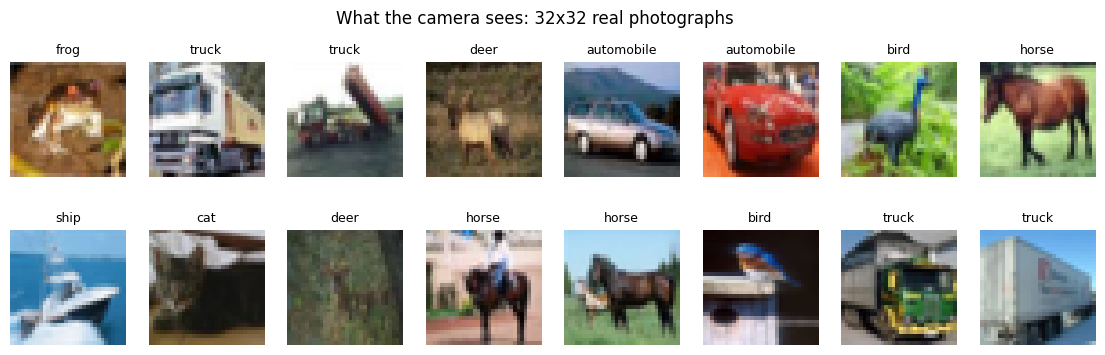

Images per class: {'airplane': np.int64(5000), 'automobile': np.int64(5000), 'bird': np.int64(5000), 'cat': np.int64(5000), 'deer': np.int64(5000), 'dog': np.int64(5000), 'frog': np.int64(5000), 'horse': np.int64(5000), 'ship': np.int64(5000), 'truck': np.int64(5000)}


In [3]:
raw = torchvision.datasets.CIFAR10("./data", train=True, download=False)  # PIL images

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.flat, range(16)):
    img, label = raw[i]
    ax.imshow(img)
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis("off")
plt.suptitle("What the camera sees: 32x32 real photographs")
plt.show()

print("Images per class:", dict(zip(CLASSES, np.bincount(raw.targets))))

In [4]:
images, labels = next(iter(train_loader))
print("images:", images.shape, "| labels:", labels.shape)
print("pixel range after normalisation: %.2f to %.2f" % (images.min(), images.max()))

images: torch.Size([128, 3, 32, 32]) | labels: torch.Size([128])
pixel range after normalisation: -1.99 to 2.13


**THINK (Part 1):** Why do we hold out a validation set instead of just using the test set to check progress? And looking at the 16 photos: what makes recognition at 32×32 resolution hard for a human, and therefore for a network?

*My answer:* We need a separate validation set so we can check progress and make choices (epochs, learning rate) without touching the test set. If we used the test set for this, our choices would be tuned to it and the final test accuracy would no longer be an honest, unbiased estimate. At 32×32 (a batch's pixels range from -1.99 to 2.13 after normalisation) an object is only a few hundred pixels: fine details such as ears, a snout or wheels shrink to 1–2 pixels, so even a human has to guess from rough shape and colour, and a network has the same limited information.

## Part 2: Build the CNN

In [5]:
class SceneCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(),
            nn.Linear(256, num_classes),      # raw scores (logits), no softmax here
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SceneCNN().to(device)
print(model)

SceneCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [6]:
x = torch.randn(1, 3, 32, 32).to(device)       # one fake 32x32 colour image
for layer in model.features:
    x = layer(x)
    print(f"{layer.__class__.__name__:<10} -> {tuple(x.shape)}")
print("Flattened length fed to the classifier:", x.numel())

Conv2d     -> (1, 32, 32, 32)
ReLU       -> (1, 32, 32, 32)
MaxPool2d  -> (1, 32, 16, 16)
Conv2d     -> (1, 64, 16, 16)
ReLU       -> (1, 64, 16, 16)
MaxPool2d  -> (1, 64, 8, 8)
Conv2d     -> (1, 128, 8, 8)
ReLU       -> (1, 128, 8, 8)
MaxPool2d  -> (1, 128, 4, 4)
Flattened length fed to the classifier: 2048


In [7]:
def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

mlp = nn.Sequential(nn.Flatten(), nn.Linear(3 * 32 * 32, 1024), nn.ReLU(), nn.Linear(1024, 10))

print(f"SceneCNN parameters : {count_params(model):>10,}")
print(f"Plain MLP parameters: {count_params(mlp):>10,}")
print()
for name, p in model.named_parameters():
    print(f"{name:<22}{str(tuple(p.shape)):<20}{p.numel():>9,}")

SceneCNN parameters :    620,362
Plain MLP parameters:  3,157,002

features.0.weight     (32, 3, 3, 3)             864
features.0.bias       (32,)                      32
features.3.weight     (64, 32, 3, 3)         18,432
features.3.bias       (64,)                      64
features.6.weight     (128, 64, 3, 3)        73,728
features.6.bias       (128,)                    128
classifier.1.weight   (256, 2048)           524,288
classifier.1.bias     (256,)                    256
classifier.3.weight   (10, 256)               2,560
classifier.3.bias     (10,)                      10


In [8]:
# My prediction: using r = r + (k-1)*j, j = j*stride, I expect 3, 4, 8, 10, 18, 22 pixels
layers = [("conv1", 3, 1), ("pool1", 2, 2), ("conv2", 3, 1),
          ("pool2", 2, 2), ("conv3", 3, 1), ("pool3", 2, 2)]   # (name, kernel, stride)
r, j = 1, 1
for name, k, s in layers:
    r = r + (k - 1) * j
    j = j * s
    print(f"{name}: each neuron sees a {r} x {r} patch of the original image")

conv1: each neuron sees a 3 x 3 patch of the original image
pool1: each neuron sees a 4 x 4 patch of the original image
conv2: each neuron sees a 8 x 8 patch of the original image
pool2: each neuron sees a 10 x 10 patch of the original image
conv3: each neuron sees a 18 x 18 patch of the original image
pool3: each neuron sees a 22 x 22 patch of the original image


**THINK (Part 2):** Which layer holds most of the parameters? (Look at the table from Cell 2.3.) Your final neurons see a 22×22 patch of a 32×32 image. What does that say about how much scene context the network can use?

*My answer:* The first fully-connected layer (classifier.1, 2048 → 256) holds 524,288 weights + 256 biases, about 85% of the 620,362 parameters; the three conv layers together have only about 93,000. A final neuron sees a 22×22 patch, which is most of the 32×32 image but not all of it, so each conv feature still describes a local region. Whole-scene context is only combined in the fully-connected layers, which is fine for small centred CIFAR objects but would be a limit for wide roadside scenes.

## Part 3: Train the Network

In [9]:
criterion = nn.CrossEntropyLoss()

images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

model.zero_grad()
loss = criterion(model(images), labels)     # forward pass + loss
loss.backward()                             # backward pass (backpropagation)

print(f"Initial loss: {loss.item():.3f}   (guessing = ln(10) = {np.log(10):.3f})")
for name, p in model.named_parameters():
    if "weight" in name:
        print(f"{name:<22} gradient norm = {p.grad.norm().item():.4f}")

Initial loss: 2.300   (guessing = ln(10) = 2.303)
features.0.weight      gradient norm = 0.0172
features.3.weight      gradient norm = 0.0653
features.6.weight      gradient norm = 0.0955
classifier.1.weight    gradient norm = 0.2220
classifier.3.weight    gradient norm = 0.0808


In [10]:
EPOCHS = 8 if device.type != "cpu" else 4      # fewer epochs on CPU
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)                          # forward pass
            loss = criterion(out, y)                # cross-entropy loss
            if train:
                optimizer.zero_grad()
                loss.backward()                     # backpropagation
                optimizer.step()                    # gradient descent step
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, train=True)
    vl, va = run_epoch(val_loader,   train=False)
    for k, v in zip(history, (tl, vl, ta, va)):
        history[k].append(v)
    print(f"Epoch {epoch}/{EPOCHS} | train loss {tl:.3f} acc {ta:.1%} "
          f"| val loss {vl:.3f} acc {va:.1%} | {time.time() - t0:.0f}s")

Epoch 1/8 | train loss 1.780 acc 34.9% | val loss 1.473 acc 47.1% | 25s


Epoch 2/8 | train loss 1.287 acc 53.7% | val loss 1.150 acc 58.3% | 25s


Epoch 3/8 | train loss 1.045 acc 63.1% | val loss 0.986 acc 64.8% | 813s


Epoch 4/8 | train loss 0.869 acc 69.6% | val loss 0.863 acc 70.1% | 26s


Epoch 5/8 | train loss 0.750 acc 73.8% | val loss 0.780 acc 72.4% | 27s


Epoch 6/8 | train loss 0.646 acc 77.5% | val loss 0.793 acc 72.6% | 29s


Epoch 7/8 | train loss 0.561 acc 80.2% | val loss 0.763 acc 73.9% | 28s


Epoch 8/8 | train loss 0.479 acc 83.2% | val loss 0.789 acc 73.5% | 27s


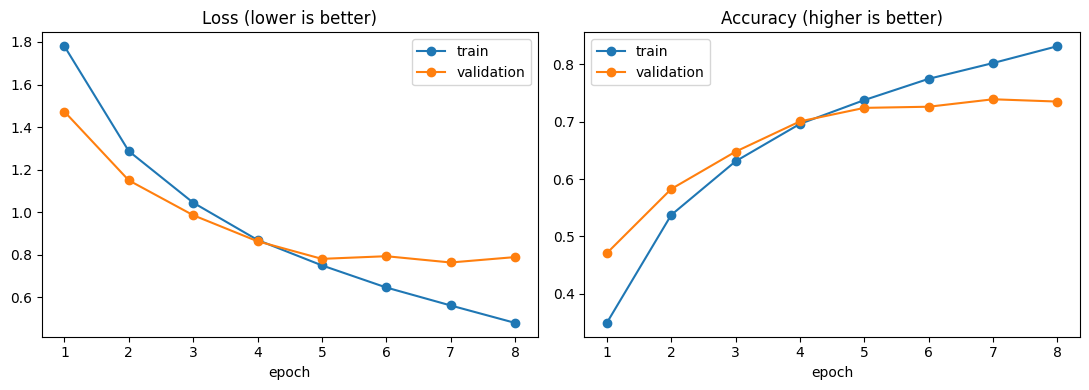

In [11]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs, history["train_loss"], "o-", label="train")
ax[0].plot(epochs, history["val_loss"],   "o-", label="validation")
ax[0].set_title("Loss (lower is better)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(epochs, history["train_acc"], "o-", label="train")
ax[1].plot(epochs, history["val_acc"],   "o-", label="validation")
ax[1].set_title("Accuracy (higher is better)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

torch.save(model.state_dict(), "scene_cnn_week3.pth")

## Part 4: Evaluate and Diagnose

Test accuracy: 73.69%

airplane   88.2%
automobile 78.6%
bird       66.4%
cat        56.5%
deer       56.8%
dog        64.7%
frog       78.8%
horse      80.8%
ship       87.4%
truck      78.7%


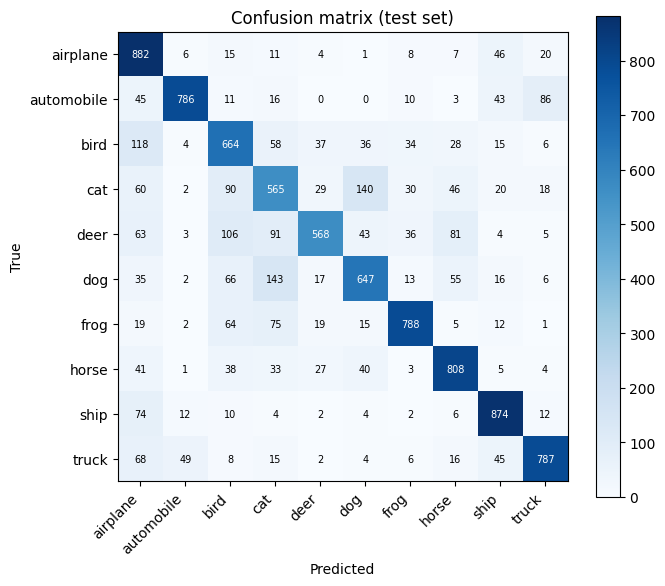


Three most common mistakes:
  dog predicted as cat: 143 times
  cat predicted as dog: 140 times
  bird predicted as airplane: 118 times


In [12]:
@torch.no_grad()
def predict_all(loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        probs.append(F.softmax(model(x.to(device)), dim=1).cpu())
        ys.append(y)
    return torch.cat(probs), torch.cat(ys)

probs, ys = predict_all(test_loader)
preds = probs.argmax(1)
print(f"Test accuracy: {(preds == ys).float().mean():.2%}\n")

cm = np.zeros((10, 10), dtype=int)                   # rows = true, cols = predicted
for t, p_ in zip(ys.numpy(), preds.numpy()):
    cm[t, p_] += 1
for c, a in zip(CLASSES, cm.diagonal() / cm.sum(1)):
    print(f"{c:<11}{a:.1%}")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test set)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im); plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)            # keep only the mistakes
print("\nThree most common mistakes:")
for idx in np.argsort(-off.ravel())[:3]:
    t, p_ = divmod(idx, 10)
    print(f"  {CLASSES[t]} predicted as {CLASSES[p_]}: {off[t, p_]} times")

C:\Users\samun\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


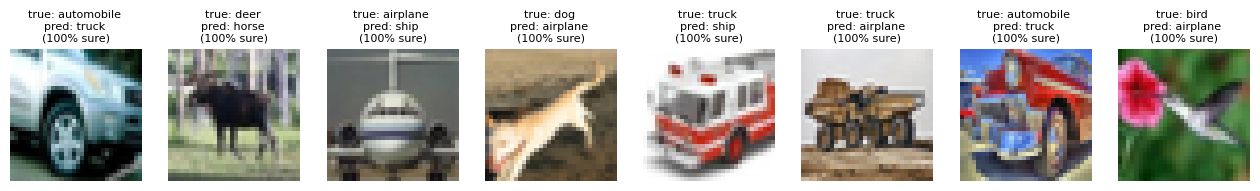

In [13]:
conf, _ = probs.max(1)
wrong = (preds != ys).nonzero().flatten()
worst = wrong[conf[wrong].argsort(descending=True)[:8]]

raw_test = torchvision.datasets.CIFAR10("./data", train=False, download=False)
fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for ax, idx in zip(axes, worst.tolist()):
    img, _ = raw_test[idx]
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"true: {CLASSES[ys[idx]]} \npred: {CLASSES[preds[idx]]} \n({conf[idx]:.0%} sure)", fontsize=8)
plt.show()

In [14]:
VEHICLES = torch.tensor([0, 1, 8, 9])            # airplane, automobile, ship, truck
true_vehicle = torch.isin(ys, VEHICLES)
pred_vehicle = torch.isin(preds, VEHICLES)

print(f"10-class (object-level) accuracy   : {(preds == ys).float().mean():.2%}")
print(f"Vehicle vs animal (scene-level)    : {(true_vehicle == pred_vehicle).float().mean():.2%}")

10-class (object-level) accuracy   : 73.69%
Vehicle vs animal (scene-level)    : 93.73%


**THINK (Part 4):** Take the top confusion from Cell 4.1. In terms of edges, textures, parts, receptive field and image resolution, why might a small CNN mix those two classes up? Why is that mistake much less harmful for the roadside-camera warning system than confusing a truck with a deer?

*My answer:* The top confusion is dog ↔ cat (dog → cat 143 times, cat → dog 140 times). Both have fur textures, similar edges and parts (pointed ears, eyes, four legs) and appear in similar poses, and at 32×32 the details that separate them (snout length, ear shape) are only a pixel or two, while a 22×22 receptive field sees similar part layouts for both. For the warning system this mistake is harmless because both are animals, so the scene-level answer (animal → warn) is still correct; confusing a truck with a deer flips the vehicle/animal decision and causes either a missed warning or a false alarm.

## Part 5: Two Quick Experiments

In [15]:
def out_size(h, k, p, s):
    return (h + 2 * p - k) // s + 1

for k, p_, s in [(3, 0, 1), (3, 0, 2), (3, 1, 1), (3, 1, 2)]:
    real = nn.Conv2d(3, 8, kernel_size=k, padding=p_, stride=s)(torch.randn(1, 3, 32, 32))
    print(f"kernel={k} padding={p_} stride={s}:  formula {out_size(32, k, p_, s)}"
          f"  | PyTorch {real.shape[-1]}")

kernel=3 padding=0 stride=1:  formula 30  | PyTorch 30
kernel=3 padding=0 stride=2:  formula 15  | PyTorch 15
kernel=3 padding=1 stride=1:  formula 32  | PyTorch 32
kernel=3 padding=1 stride=2:  formula 16  | PyTorch 16


In [16]:
sub_loader = DataLoader(Subset(train_set, range(10000)), batch_size=BATCH,
                        shuffle=True, num_workers=2)

def quick_lr_test(lr, epochs=2):
    torch.manual_seed(SEED)
    m = SceneCNN().to(device)
    opt = torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9)
    for _ in range(epochs):
        m.train()
        for x, y in sub_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = criterion(m(x), y)
            loss.backward()
            opt.step()
    m.eval(); correct = 0
    with torch.no_grad():
        for x, y in val_loader:
            correct += (m(x.to(device)).argmax(1).cpu() == y).sum().item()
    return loss.item(), correct / len(val_set)

# My prediction: lr=0.1 overshoots (loss stays high), lr=0.01 is best, lr=0.001 learns too slowly
for lr in [0.1, 0.01, 0.001]:
    last_loss, val_acc = quick_lr_test(lr)
    print(f"lr = {lr:<6} final batch loss = {last_loss:.3f}   validation accuracy = {val_acc:.1%}")

lr = 0.1    final batch loss = 1.674   validation accuracy = 39.6%


lr = 0.01   final batch loss = 1.731   validation accuracy = 38.4%


lr = 0.001  final batch loss = 2.299   validation accuracy = 12.4%


**Result vs prediction:** lr = 0.001 was clearly too small (12.4% validation accuracy, final batch loss 2.299, still near ln 10 = 2.303), as predicted. But lr = 0.1 did not diverge in this run: after only 2 epochs it reached 39.6%, slightly above lr = 0.01 (38.4%). With momentum 0.9 a rate of 0.1 is on the edge of stability, so it can work in one short run and fail in another; 0.01 remains the safer choice for full training.

## Reflection

**1. Efficiency:** The CNN has 620,362 parameters against 3,157,002 for the plain fully-connected network (about 5× fewer), yet it is the better image model because of **local connectivity** (each neuron only looks at a small 3×3 neighbourhood, where image structure such as edges lives) and **weight sharing** (the same filter is reused at every position, so a pattern learned in one place is recognised everywhere). Together these build in translation equivariance, so the network does not need separate weights for every pixel position.

**2. Diagnosis:** In epoch 1 the model was at 34.9% train / 47.1% validation accuracy; by epoch 8 training accuracy had climbed steadily to 83.2% while validation accuracy flattened at about 72–74% from epoch 5 (73.5% at the end), and validation loss reached its minimum (0.763) at epoch 7 before rising again (0.789). This growing gap of about 10 points means the model has started to overfit. I would try data augmentation (random flips and crops) first, because it shows the network new variations of the same images and directly fights memorisation without changing the model.

**3. Scene vs object:** The 10-class test accuracy was 73.69%, while vehicle-vs-animal accuracy was 93.73%, because most mistakes stay inside a group (e.g. dog ↔ cat 283 times). A scene-understanding system should therefore be evaluated on the decision it actually has to make, and its errors should be weighted by cost: cross-group errors such as bird → airplane (118 times) matter far more for a deer warning than cat ↔ dog. A hierarchical design (first vehicle vs animal, then the detailed class) and cost-aware metrics fit this better than overall accuracy alone.